# 19. Extraordinary Optical Transmission (EOT) in Subwavelength Metallic Hole Arrays

## Physical Motivation & Learning Objectives
In 1998, Ebbesen et al. discovered that subwavelength hole arrays in metallic films transmit substantially more light than predicted by classical Bethe aperture theory. This **Extraordinary Optical Transmission (EOT)** is mediated by Surface Plasmon Polaritons (SPPs) and localized cavity resonances ([Liu & Lalanne, Nature 452, 728 (2008)](https://doi.org/10.1038/nature06762)).
In this tutorial:
1. We simulate a subwavelength square hole array in a gold film.
2. We identify the plasmonic EOT transmission peak.

> [!NOTE]
> **Meshing Workflow: Native Netgen CSG (`examples_netgen/`)**
> Square apertures meshed in-memory via Netgen CSG.



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



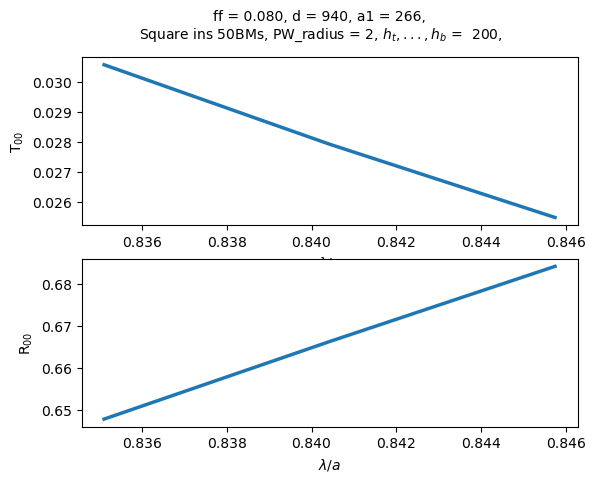

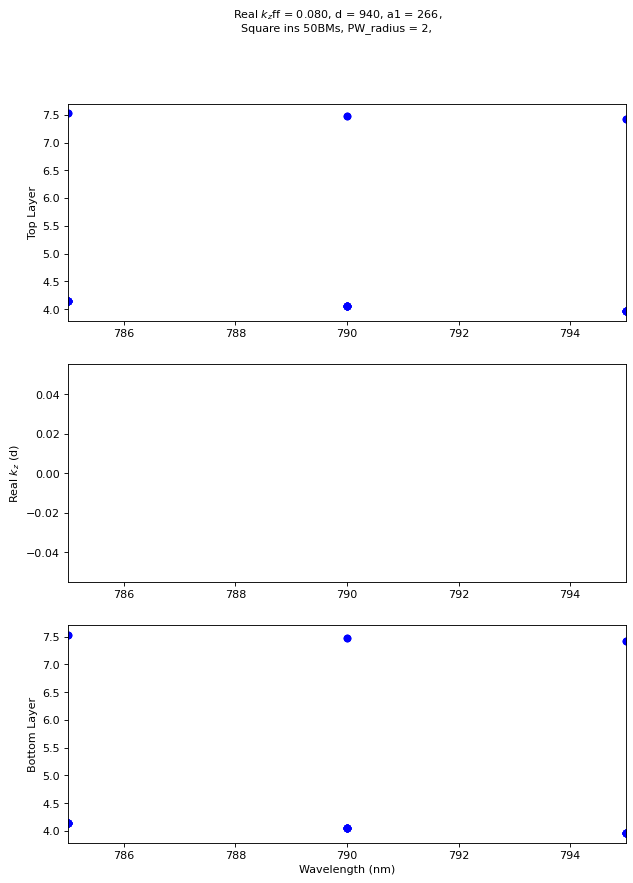

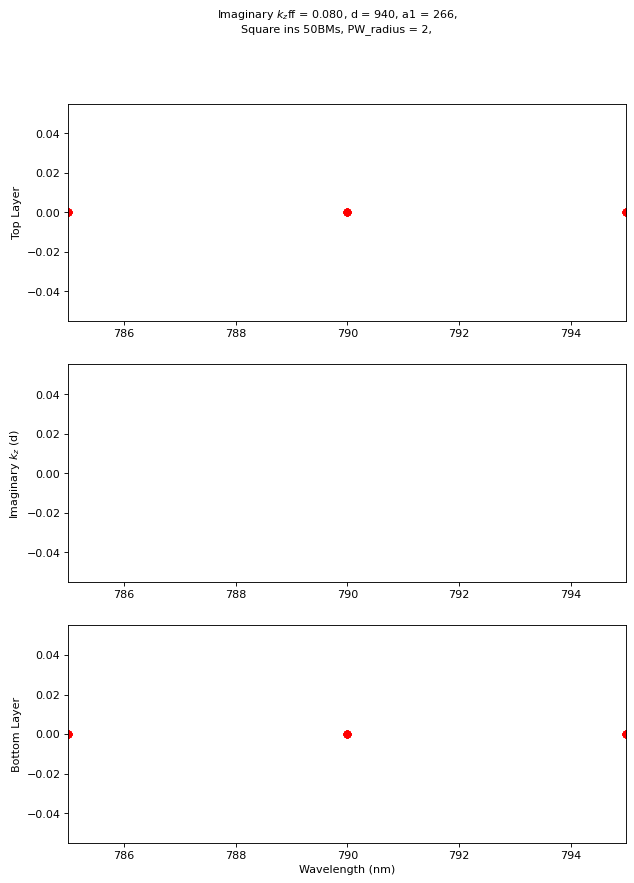

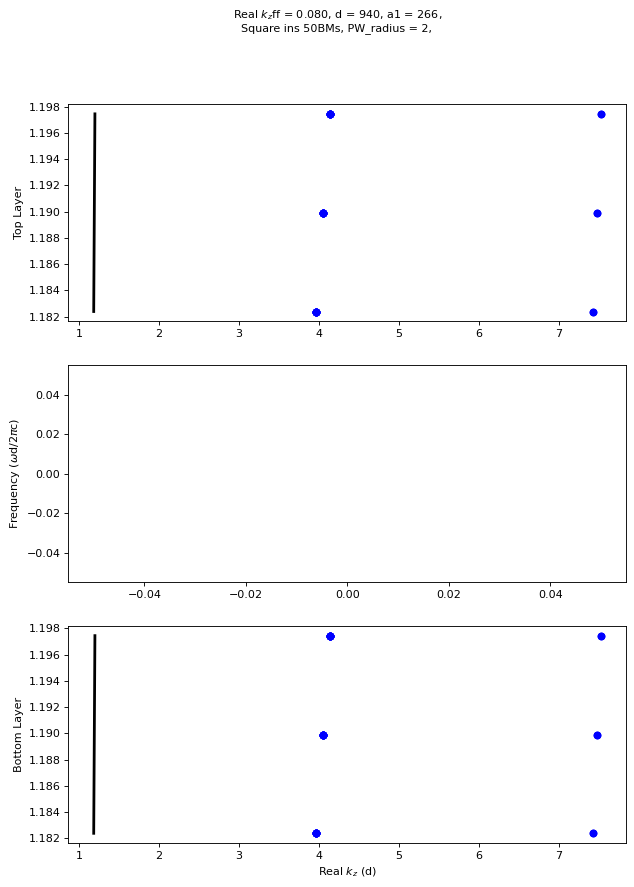

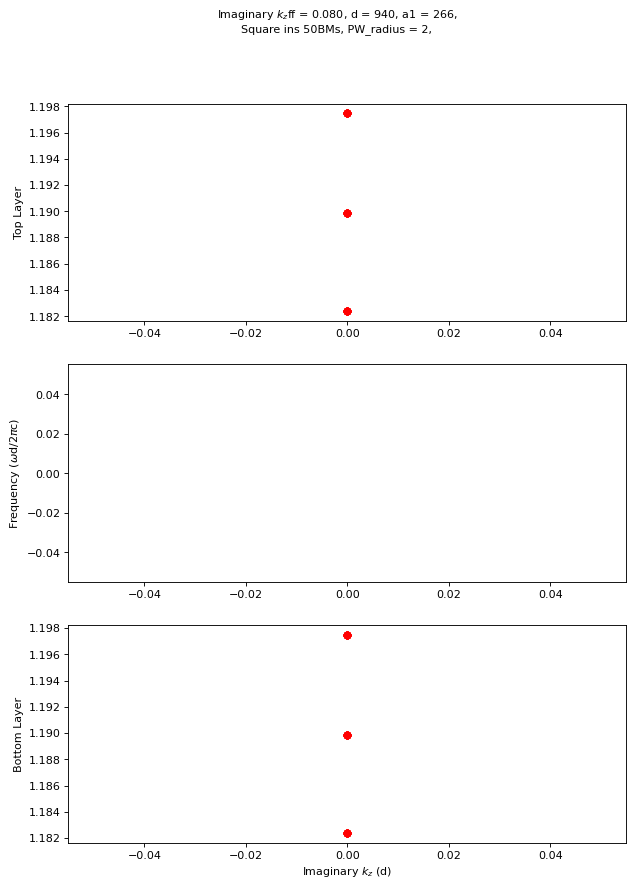

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

period = 940.0
diam1 = 266.0
height_nm = 200.0

wavelengths = np.array([785.0, 790.0, 795.0])
light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

NHs = objects.NanoStruct(
    '2D_array', period, diam1, height_nm=height_nm,
    inclusion_a=materials.Air, background=materials.Au, loss=True,
    inc_shape='square'
)

strate = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Air, loss=False)

def simulate_stack(light):
    sim_NHs    = NHs.calc_modes(light, num_BMs=50)
    sim_strate = strate.calc_modes(light)
    stk = Stack((sim_strate, sim_NHs, sim_strate), heights_nm=[height_nm])
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(l) for l in light_list]

wls_normed = wavelengths / period
wl_list = [s for s in stacks_list]
fig_eot = plotting.EOT_plot(wl_list, wls_normed, add_name='_h0', savetxt=False)
plt.show()

fig_om = plotting.omega_plot(wl_list, wavelengths)
plt.show()


## EOT Geometry Setup: Subwavelength Au Hole Array


## EOT Transmission Peak Spectrum


## Physical Interpretation
Resonant surface plasmon modes excited on the top and bottom metal surfaces tunnel through the subwavelength apertures, yielding strong forward transmission peaks.
